# HW5 - Backprop and Optimization

green = forward values, red = gradients (going backwards, start with 1)

gate rules from the slides:
- add: gradient goes to both sides
- multiply: swap the inputs
- max/relu: gradient only goes to the bigger one

In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

## Q1 chain rule
f = x*y + z, q = x*y, x=-2 y=5 z=-4

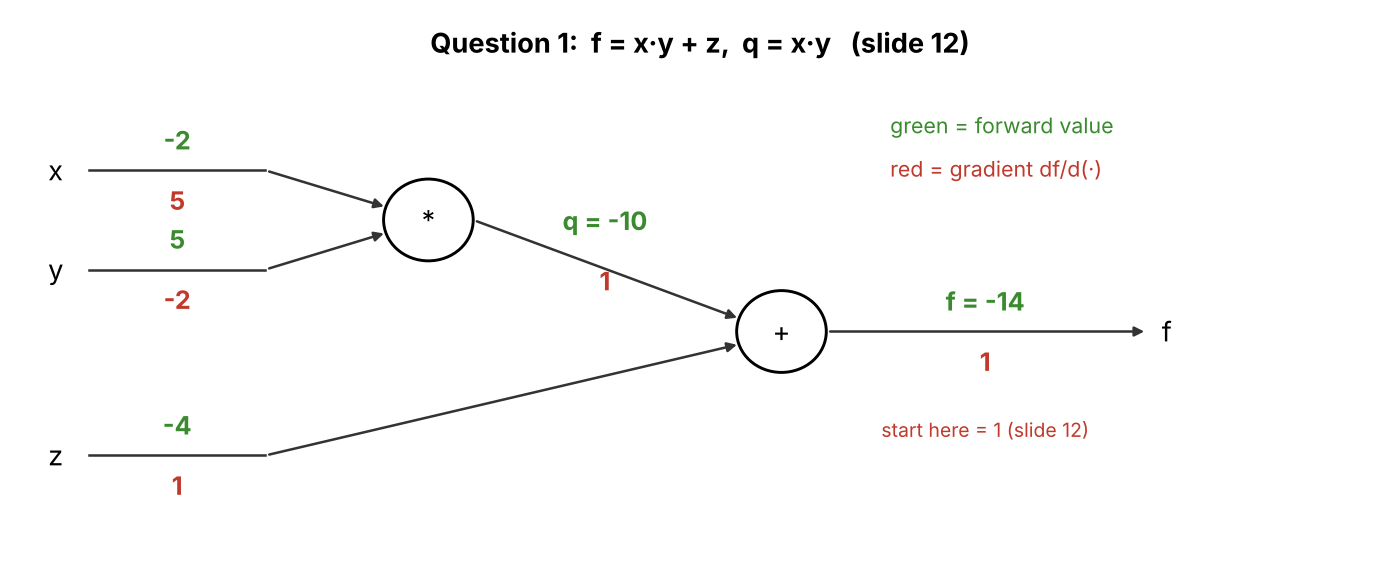

In [ ]:
x, y, z = -2.0, 5.0, -4.0

# forward
q = x * y    # -10
f = q + z    # -14
print(q, f)

backward - start with 1, the add gate just passes it, multiply swaps x and y

In [ ]:
df_df = 1.0
df_dq = 1.0 * df_df   # 1
df_dz = 1.0 * df_df   # 1
df_dx = y * df_dq     # 5
df_dy = x * df_dq     # -2
print(df_dz, df_dq, df_dx, df_dy)

In [ ]:
def chain_rule():
    x, y, z = -2.0, 5.0, -4.0
    q = x * y
    f = q + z
    df_df = 1.0
    df_dq = 1.0 * df_df
    df_dz = 1.0 * df_df
    df_dx = y * df_dq
    df_dy = x * df_dq
    return float(df_dz), float(df_dq), float(df_dx), float(df_dy)

print(chain_rule())

## Q2 relu
y = relu(w0*x0 + w1*x1 + w2), x = [-1,-2], w = [2,-3,-3]

same as the sigmoid example but relu at the end

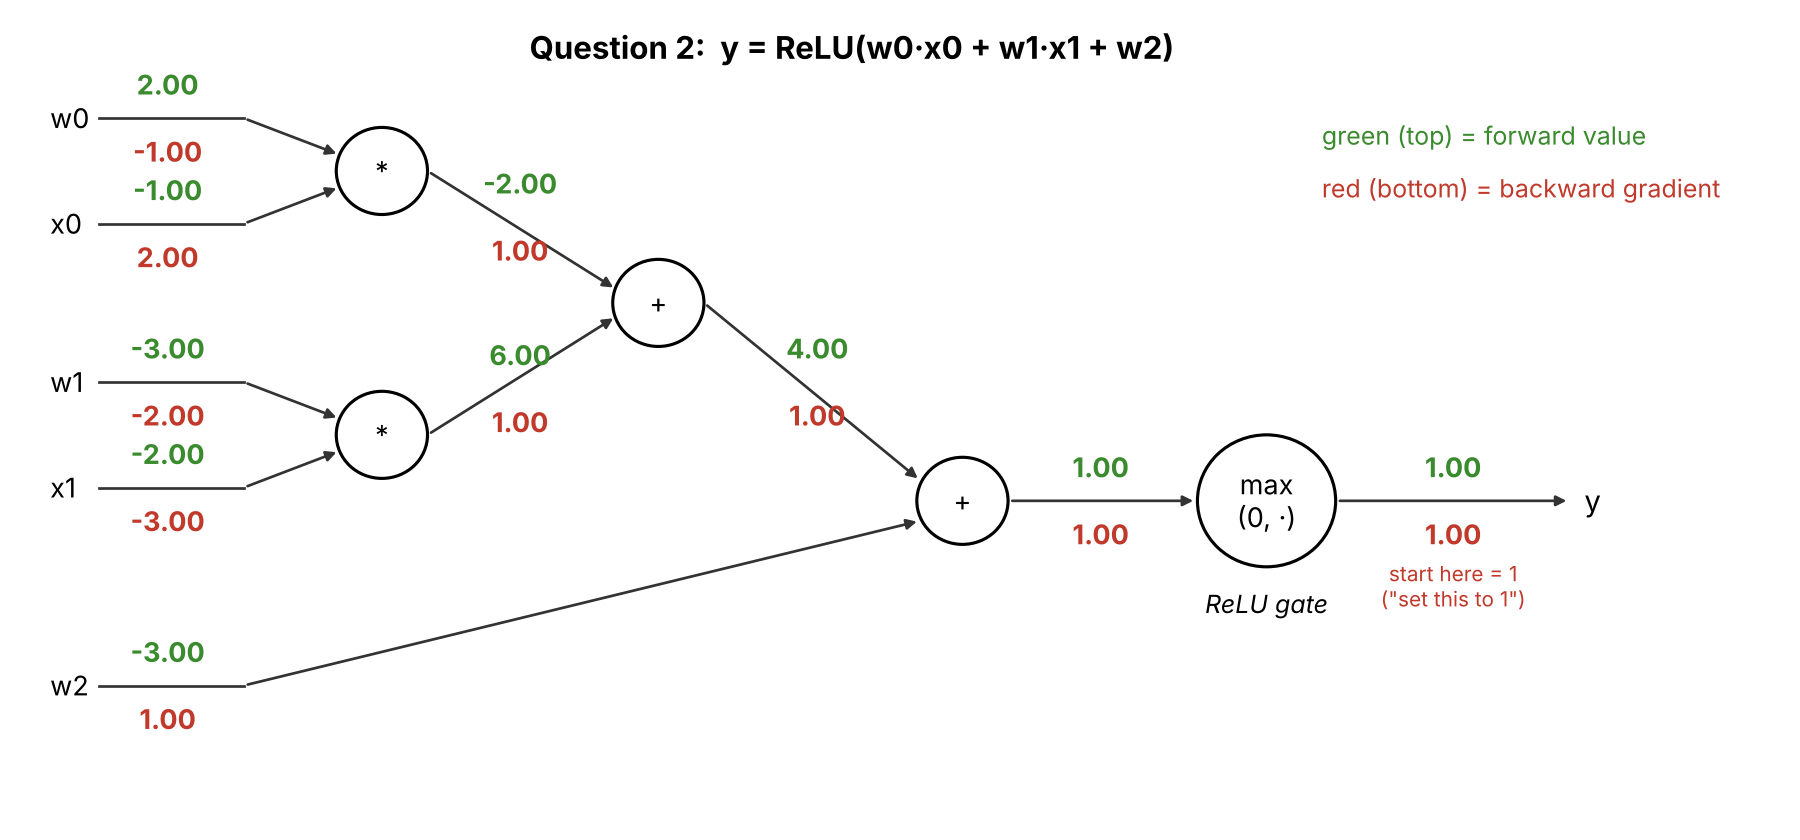

In [ ]:
x0, x1 = -1.0, -2.0
w0, w1, w2 = 2.0, -3.0, -3.0

# forward
a = w0 * x0      # -2
b = w1 * x1      # 6
c = a + b        # 4
s = c + w2       # 1
y = max(0.0, s)  # 1
print(a, b, c, s, y)

backward - s is positive so relu lets the gradient through (if it was negative everything would be 0)

In [ ]:
dy = 1.0
ds = dy * (1.0 if s > 0 else 0.0)   # 1
dc, dw2 = ds, ds
da, db = dc, dc
dw0, dx0 = x0 * da, w0 * da   # swap
dw1, dx1 = x1 * db, w1 * db
print("dx:", [dx0, dx1])
print("dw:", [dw0, dw1, dw2])

In [ ]:
def ReLU():
    x0, x1 = -1.0, -2.0
    w0, w1, w2 = 2.0, -3.0, -3.0
    s = w0 * x0 + w1 * x1 + w2
    y = max(0.0, s)
    dy_dy = 1.0
    dy_ds = dy_dy * (1.0 if s > 0 else 0.0)
    dx = [w0 * dy_ds, w1 * dy_ds]
    dw = [x0 * dy_ds, x1 * dy_ds, 1.0 * dy_ds]
    return dx, dw

print(ReLU())

## Q3 sigmoid with autograd
same numbers as the slide example, answers to 4 decimals

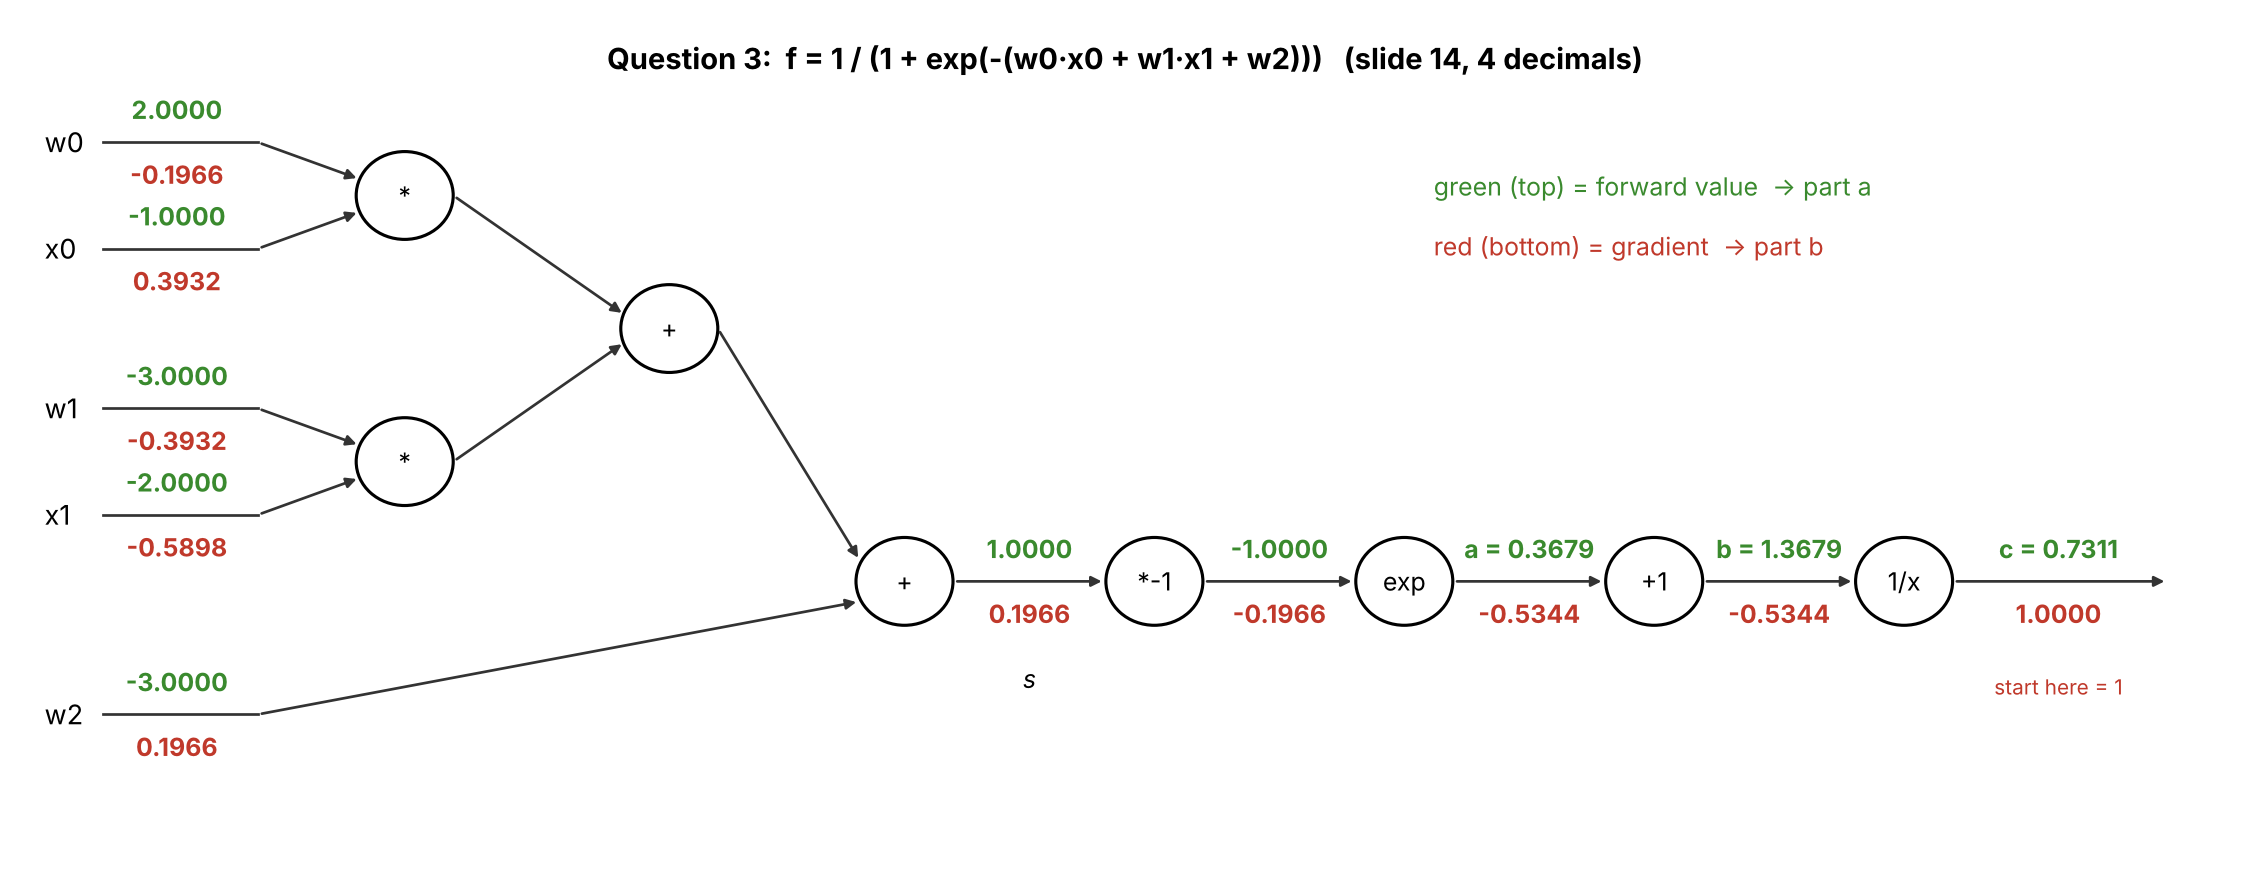

In [ ]:
w0 = torch.tensor(2.0, requires_grad=True)
x0 = torch.tensor(-1.0, requires_grad=True)
w1 = torch.tensor(-3.0, requires_grad=True)
x1 = torch.tensor(-2.0, requires_grad=True)
w2 = torch.tensor(-3.0, requires_grad=True)

# forward
s = w0 * x0 + w1 * x1 + w2   # 1
a = torch.exp(-s)            # 0.37
b = 1 + a                    # 1.37
c = 1 / b                    # 0.73
print(round(a.item(), 4), round(b.item(), 4), round(c.item(), 4))

backward - c.backward() does all the gates for us. retain_grad so i can check the middle values with the slide

In [ ]:
for t in (s, a, b):
    t.retain_grad()
c.backward()
print("b:", round(b.grad.item(), 4), "a:", round(a.grad.item(), 4), "s:", round(s.grad.item(), 4))
for name, t in [("w0", w0), ("x0", x0), ("w1", w1), ("x1", x1), ("w2", w2)]:
    print(name, round(t.grad.item(), 4))

note: gradient at s is only 0.1966 here (relu gave 1), sigmoid makes it smaller

In [ ]:
def _sigmoid_graph():
    w0 = torch.tensor(2.0, requires_grad=True)
    x0 = torch.tensor(-1.0, requires_grad=True)
    w1 = torch.tensor(-3.0, requires_grad=True)
    x1 = torch.tensor(-2.0, requires_grad=True)
    w2 = torch.tensor(-3.0, requires_grad=True)
    s = w0 * x0 + w1 * x1 + w2
    a = torch.exp(-s)
    b = 1 + a
    c = 1 / b
    return (w0, x0, w1, x1, w2), (a, b, c)

def chain_rule_a():
    _, (a, b, c) = _sigmoid_graph()
    a = round(a.item(), 4)
    b = round(b.item(), 4)
    c = round(c.item(), 4)
    return a, b, c

def chain_rule_b():
    (w0, x0, w1, x1, w2), (a, b, c) = _sigmoid_graph()
    c.backward()
    gw0 = round(w0.grad.item(), 4)
    gx0 = round(x0.grad.item(), 4)
    gw1 = round(w1.grad.item(), 4)
    gx1 = round(x1.grad.item(), 4)
    gw2 = round(w2.grad.item(), 4)
    return gw0, gx0, gw1, gx1, gw2

print(chain_rule_a())
print(chain_rule_b())

## Q4 tanh + MSE loss
w = [5,2], x = [-1,4], bias = -2, ground truth = 1, lr = 0.1

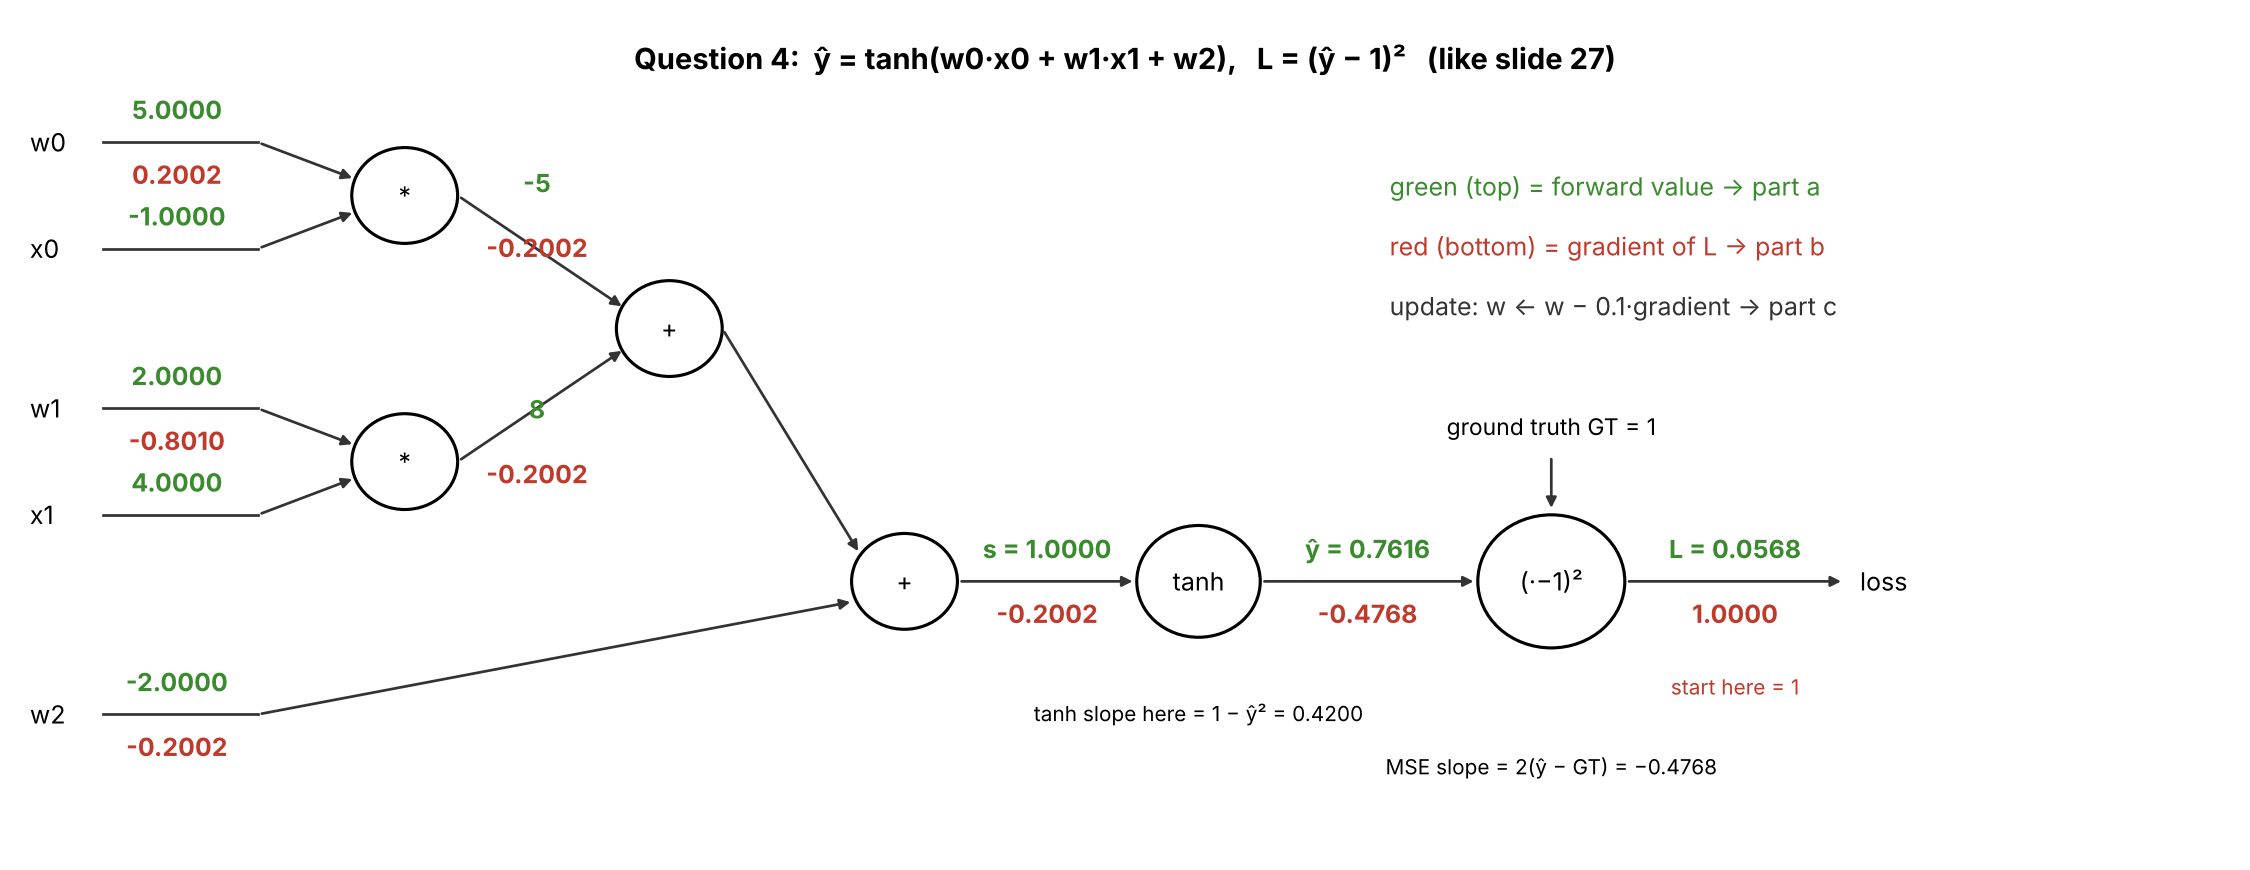

In [ ]:
w = torch.tensor([5.0, 2.0, -2.0], requires_grad=True)
x = torch.tensor([-1.0, 4.0])

# (a) forward
s = w[0] * x[0] + w[1] * x[1] + w[2]   # 1
y_hat = torch.tanh(s)                  # 0.7616
print(s.item(), round(y_hat.item(), 4))

In [ ]:
# (b) loss and backward
loss = (y_hat - 1.0) ** 2
s.retain_grad()
y_hat.retain_grad()
loss.backward()
print("loss:", round(loss.item(), 4))
print("y_hat grad:", round(y_hat.grad.item(), 4))
print("s grad:", round(s.grad.item(), 4))
print("w grads:", [round(g, 4) for g in w.grad.tolist()])

In [ ]:
# (c) update w = w - lr * grad
lr = 0.1
with torch.no_grad():
    w -= lr * w.grad
print([round(v, 4) for v in w.tolist()])

# check loss went down
with torch.no_grad():
    y_new = torch.tanh(w[0] * x[0] + w[1] * x[1] + w[2])
    print("new loss:", round(((y_new - 1) ** 2).item(), 4))

In [ ]:
def _tanh_net():
    w = torch.tensor([5.0, 2.0, -2.0], requires_grad=True)
    x = torch.tensor([-1.0, 4.0])
    y_hat = torch.tanh(w[0] * x[0] + w[1] * x[1] + w[2])
    return w, y_hat

def backprop_a():
    _, y_hat = _tanh_net()
    y_hat = y_hat.item()
    return y_hat

def backprop_b():
    w, y_hat = _tanh_net()
    loss = (y_hat - 1.0) ** 2
    loss.backward()
    gw0, gw1, gw2 = [g.item() for g in w.grad]
    return gw0, gw1, gw2

def backprop_c():
    lr = 0.1
    w, y_hat = _tanh_net()
    loss = (y_hat - 1.0) ** 2
    loss.backward()
    with torch.no_grad():
        w -= lr * w.grad
    w0, w1, w2 = [v.item() for v in w]
    return  w0, w1, w2

print(backprop_a())
print(backprop_b())
print(backprop_c())

## Q5 newton and sgd
paraboloid image 256x256, min at (128,128). derivatives using conv2d

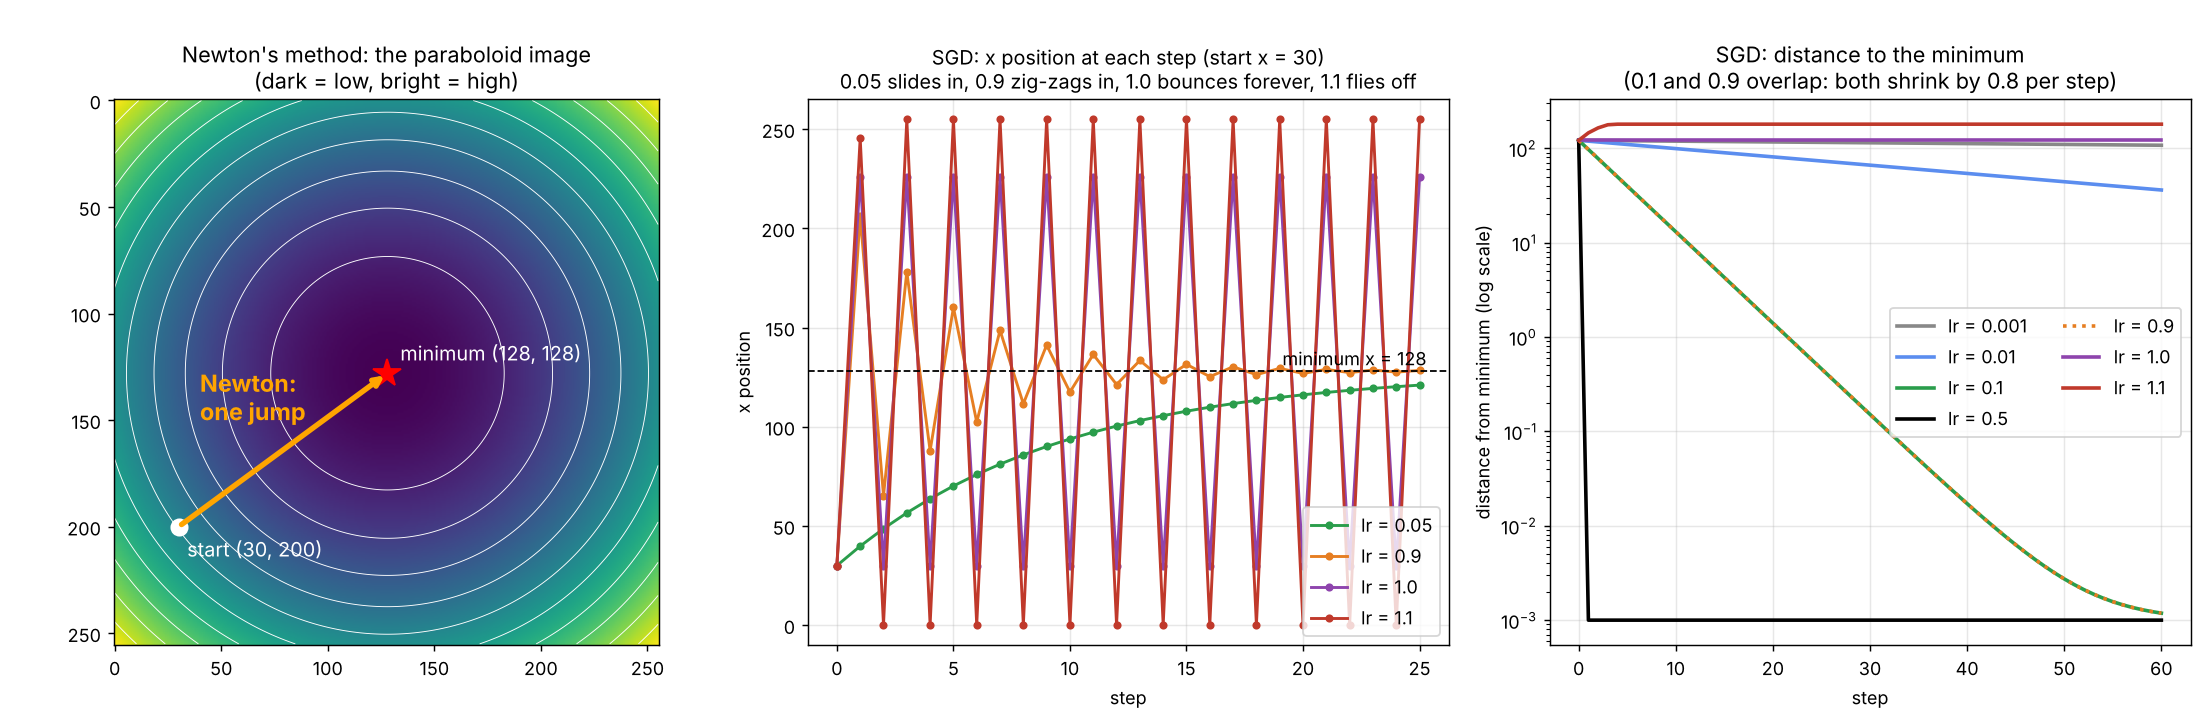

In [ ]:
def constructParaboloid(w=256, h=256):
    img = np.zeros((w, h), np.float32)
    for x in range(w):
        for y in range(h):
            img[y, x] = (x - w / 2) ** 2 + (y - h / 2) ** 2
    return img

img = constructParaboloid()
plt.imshow(img)
plt.colorbar()
plt.show()
print(img[128, 128], img[200, 30])   # 0 at the min, 14788 at start

derivatives with kernels:
- slope: [-0.5, 0, 0.5]
- curvature: [1, -2, 1]

In [ ]:
P = torch.tensor(img).unsqueeze(0).unsqueeze(0)   # conv2d needs (1,1,H,W)

def conv(kernel):
    k = torch.tensor(kernel, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    return F.conv2d(P, k, padding=(k.shape[2] // 2, k.shape[3] // 2))[0, 0]

fx = conv([[-0.5, 0.0, 0.5]])
fy = conv([[-0.5], [0.0], [0.5]])
fxx = conv([[1.0, -2.0, 1.0]])
fyy = conv([[1.0], [-2.0], [1.0]])
fxy = conv([[0.25, 0, -0.25], [0, 0, 0], [-0.25, 0, 0.25]])

r, c = 200, 30   # start point (row = y, col = x)
print(fx[r, c].item(), fy[r, c].item())
print(fxx[r, c].item(), fyy[r, c].item(), fxy[r, c].item())

newton step: new = old - H^-1 * g

In [ ]:
g = torch.tensor([fx[r, c], fy[r, c]])
H = torch.tensor([[fxx[r, c], fxy[r, c]],
                  [fxy[r, c], fyy[r, c]]])
step = torch.linalg.solve(H, g)
print(30 - step[0].item(), 200 - step[1].item())   # gets to 128,128 in one step

sgd idea (just testing with the formula)

In [ ]:
x, y, lr = 30.0, 200.0, 0.1
for i in range(200):
    gx, gy = 2 * (x - 128), 2 * (y - 128)
    x, y = x - lr * gx, y - lr * gy
    if i < 5:
        print(i, round(x, 2), round(y, 2))
print("final:", round(x), round(y))

actual functions. _sample is for reading the image at decimal positions (blends the 4 nearby pixels)

In [ ]:
def _derivative_images(paraboloid):
    def conv(kernel):
        k = torch.tensor(kernel, dtype=torch.float32)
        k = k.unsqueeze(0).unsqueeze(0)
        pad = (k.shape[2] // 2, k.shape[3] // 2)
        return F.conv2d(paraboloid, k, padding=pad)[0, 0]
    fx = conv([[-0.5, 0.0, 0.5]])
    fy = conv([[-0.5], [0.0], [0.5]])
    fxx = conv([[1.0, -2.0, 1.0]])
    fyy = conv([[1.0], [-2.0], [1.0]])
    fxy = conv([[0.25, 0.0, -0.25],
                [0.0, 0.0, 0.0],
                [-0.25, 0.0, 0.25]])
    return fx, fy, fxx, fyy, fxy

def _sample(img, x, y):
    H, W = img.shape
    x = min(max(x, 1.0), W - 2.0)
    y = min(max(y, 1.0), H - 2.0)
    c0, r0 = int(np.floor(x)), int(np.floor(y))
    c1, r1 = min(c0 + 1, W - 1), min(r0 + 1, H - 1)
    dx, dy = x - c0, y - r0
    top = (1 - dx) * img[r0, c0].item() + dx * img[r0, c1].item()
    bottom = (1 - dx) * img[r1, c0].item() + dx * img[r1, c1].item()
    return (1 - dy) * top + dy * bottom

def newtonMethod(x0, y0):
    paraboloid = torch.tensor([constructParaboloid()]).squeeze()
    paraboloid = torch.unsqueeze(paraboloid, 0)
    paraboloid = torch.unsqueeze(paraboloid, 0)
    fx, fy, fxx, fyy, fxy = _derivative_images(paraboloid)
    H, W = fx.shape
    x, y = float(x0), float(y0)
    for _ in range(100):
        g = torch.tensor([_sample(fx, x, y), _sample(fy, x, y)])
        hxy = _sample(fxy, x, y)
        Hm = torch.tensor([[_sample(fxx, x, y), hxy],
                           [hxy, _sample(fyy, x, y)]])
        step = torch.linalg.solve(Hm, g)
        x, y = x - step[0].item(), y - step[1].item()
        x = min(max(x, 0), W - 1)
        y = min(max(y, 0), H - 1)
        if abs(step[0].item()) < 1e-6 and abs(step[1].item()) < 1e-6:
            break
    final_x, final_y = int(round(x)), int(round(y))
    return final_x, final_y

def sgd(x0, y0, lr=0.001):
    paraboloid = torch.tensor([constructParaboloid()]).squeeze()
    paraboloid = torch.unsqueeze(paraboloid, 0)
    paraboloid = torch.unsqueeze(paraboloid, 0)
    fx, fy, _, _, _ = _derivative_images(paraboloid)
    H, W = fx.shape
    x, y = float(x0), float(y0)
    for _ in range(100000):
        gx, gy = _sample(fx, x, y), _sample(fy, x, y)
        new_x = min(max(x - lr * gx, 0), W - 1)
        new_y = min(max(y - lr * gy, 0), H - 1)
        moved = abs(new_x - x) + abs(new_y - y)
        x, y = new_x, new_y
        if moved < 1e-4:
            break
    final_x, final_y = int(round(x)), int(round(y))
    return final_x, final_y

print(newtonMethod(30, 200))
print(sgd(30, 200, lr=0.001))

trying different learning rates (takes about a minute)

In [ ]:
for lr in [0.0001, 0.001, 0.01, 0.1, 0.5, 0.9, 1.0, 1.1]:
    print(lr, sgd(30, 200, lr=lr))

### report notes
1. each step the distance gets multiplied by (1 - 2*lr). small lr = slow, bigger = faster, 0.5 = one step, between 0.5 and 1 it zigzags but still gets there
2. lr > 1 diverges (1.1 ends at the edge 0,255). lr = 1 just bounces back and forth forever

## all answers

In [ ]:
print(chain_rule())
print(ReLU())
print(chain_rule_a())
print(chain_rule_b())
print(backprop_a())
print(backprop_b())
print(backprop_c())
print(newtonMethod(30, 200))
print(sgd(30, 200, lr=0.001))